# 05: Resultado final no teste (tasks 21 e 23)

**Pergunta do projeto:** o STGCN prevê a taxa semanal de internações por dengue nos 79 municípios do RJ melhor que os baselines honestos?

Este notebook mostra a avaliação no teste (2016 a 2021). **Cada modelo é avaliado no teste uma única vez**, com a configuração congelada pela validação (2013 a 2015):

| Escolha | Valor | De onde veio |
| --- | --- | --- |
| Modelo | STGCN, Chebyshev K = 3, oculto 32, grafo k-NN geográfico | tasks 15 e 16 |
| Otimizador e agenda | AdamW, η = 0,01, warmup + cosseno, 920 passos | task 19 |
| Perda | Huber (δ = 1) em `log1p` | task 20 |
| Época | a de menor perda na validação | executor (task 18) |
| Transformer espacial | mesmo protocolo do STGCN final, η = 0,01 | task 23 (`03b_transformer`) |

As configurações estão congeladas em `configs/final.yaml` e `configs/transformer.yaml`. O script abaixo treina tudo de novo com 3 seeds, usando só o treino e a validação, e só então prevê o teste. Ele se recusa a avaliar um modelo que já está nos resultados:

```
python -m dengue.avaliacao_final   # cerca de 20 min; gera results/teste_final*.csv
```

Este notebook só lê os resultados.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dengue import dados

RES = dados.RAIZ / 'results'
r = pd.read_csv(RES / 'teste_final.csv')
series = pd.read_csv(RES / 'teste_final_series.csv', parse_dates=['data'])
munic = pd.read_csv(RES / 'teste_final_municipios.csv', index_col='municipio')

nomes = {'persistencia': 'Persistência', 'climatologia_mediana': 'Climatologia (mediana)',
         'lstm': 'LSTM sem grafo', 'stgcn_base': 'STGCN, Adam 1e-3 (baseline)',
         'stgcn_sem_grafo': 'STGCN final sem grafo (A = I)', 'stgcn_final': 'STGCN final',
         'transformer_sem_atencao': 'Transformer sem atenção', 'transformer': 'Transformer espacial'}
cores = {'persistencia': 'tab:gray', 'climatologia_mediana': 'silver', 'lstm': 'tab:orange',
         'stgcn_base': 'lightsteelblue', 'stgcn_sem_grafo': 'tab:cyan', 'stgcn_final': 'tab:blue',
         'transformer_sem_atencao': 'plum', 'transformer': 'tab:purple'}
ordem = list(nomes)

# Conferência: na validação, o STGCN final repete a Huber da task 20, seed a seed
val_final = r.query("modelo == 'stgcn_final' and particao == 'validacao'")['mae'].round(4)
print('MAE na validação, STGCN final por seed:', val_final.tolist(), '(task 20: 0,4379 / 0,4426 / 0,4453)')

colunas = ['mae', 'rmse', 'mae_surto', 'mae_calmaria', 'vies_surto', 'vies_calmaria']
g = r.groupby(['particao', 'modelo'])[colunas + [f'mae_h{h}' for h in range(1, 5)]]
media, desvio = g.mean(), g.std().fillna(0)

# Tabela final congelada: teste, média ± desvio de 3 seeds (baselines sem seed: desvio 0)
teste_m, teste_d = media.loc['teste'].loc[ordem], desvio.loc['teste'].loc[ordem]
tabela = pd.concat([teste_m[colunas].add_suffix('_media'), teste_d[colunas].add_suffix('_desvio')],
                   axis=1)
tabela.round(4).to_csv(RES / 'teste_final_tabela.csv')
pd.DataFrame({c: [f'{teste_m.loc[m, c]:.3f} ± {teste_d.loc[m, c]:.3f}' for m in ordem]
              for c in colunas}, index=[nomes[m] for m in ordem])

MAE na validação, STGCN final por seed: [0.4379, 0.4426, 0.4453] (task 20: 0,4379 / 0,4426 / 0,4453)


,mae,rmse,mae_surto,mae_calmaria,vies_surto,vies_calmaria
Persistência,0.234 ± 0.000,1.276 ± 0.000,2.057 ± 0.000,0.163 ± 0.000,0.252 ± 0.000,0.019 ± 0.000
Climatologia (mediana),0.300 ± 0.000,1.662 ± 0.000,3.141 ± 0.000,0.189 ± 0.000,-3.086 ± 0.000,-0.130 ± 0.000
LSTM sem grafo,0.213 ± 0.003,0.988 ± 0.012,1.387 ± 0.021,0.167 ± 0.003,-0.325 ± 0.055,0.025 ± 0.004
"STGCN, Adam 1e-3 (baseline)",0.216 ± 0.013,0.982 ± 0.018,1.512 ± 0.033,0.165 ± 0.014,-0.287 ± 0.076,0.021 ± 0.017
STGCN final sem grafo (A = I),0.188 ± 0.003,0.922 ± 0.013,1.300 ± 0.023,0.144 ± 0.004,-0.469 ± 0.079,0.001 ± 0.005
STGCN final,0.187 ± 0.011,0.923 ± 0.015,1.326 ± 0.025,0.142 ± 0.011,-0.448 ± 0.187,0.000 ± 0.016
Transformer sem atenção,0.210 ± 0.004,1.009 ± 0.013,1.571 ± 0.038,0.157 ± 0.005,-0.300 ± 0.142,0.019 ± 0.004
Transformer espacial,0.207 ± 0.017,1.022 ± 0.079,1.950 ± 0.344,0.139 ± 0.006,0.806 ± 0.463,-0.005 ± 0.005


### Pergunta 1: no teste, o STGCN final supera os baselines, o LSTM e o Transformer?

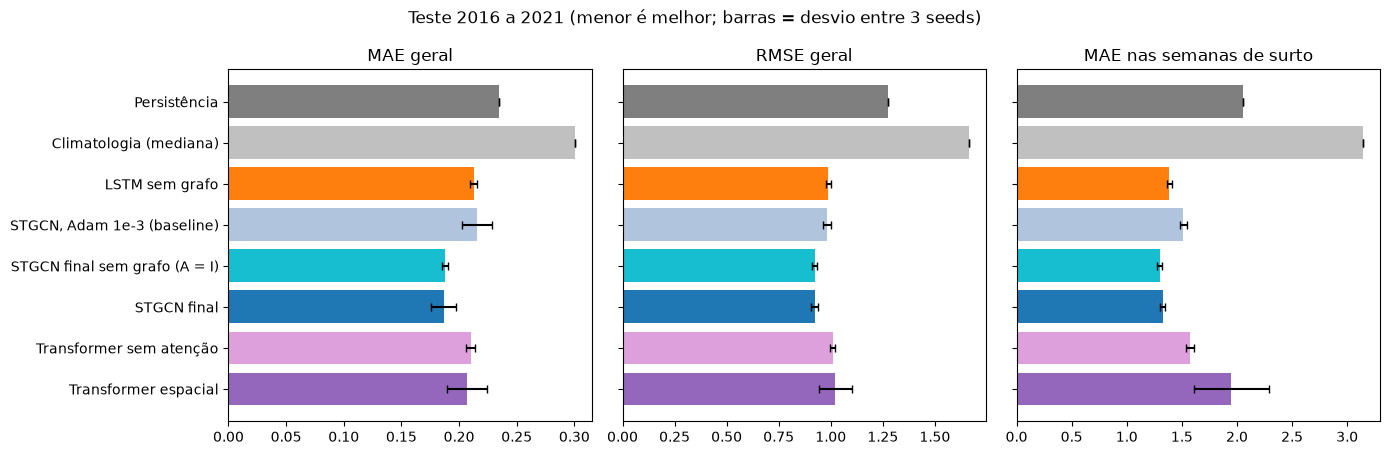

In [2]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4.6))
titulos = {'mae': 'MAE geral', 'rmse': 'RMSE geral', 'mae_surto': 'MAE nas semanas de surto'}
for ax, c in zip(eixos, titulos):
    ax.barh([nomes[m] for m in ordem], teste_m[c], xerr=teste_d[c], capsize=3,
            color=[cores[m] for m in ordem])
    ax.set_title(titulos[c])
    ax.invert_yaxis()
for ax in eixos[1:]:
    ax.set_yticklabels([])
fig.suptitle('Teste 2016 a 2021 (menor é melhor; barras = desvio entre 3 seeds)')
plt.tight_layout()
plt.show()

**Conclusão:** sim. No teste, o STGCN final tem MAE 0,187 ± 0,011, RMSE 0,923 ± 0,015 e MAE em surto 1,33 ± 0,03.
- **Contra a persistência**, o melhor baseline: −20% no MAE, −28% no RMSE e −36% no MAE em surto.
- **Contra o LSTM**: −12% no MAE, −7% no RMSE e −4% no MAE em surto.
- **Contra o mesmo STGCN treinado com o protocolo antigo** (Adam 1e-3, agenda constante): −13% no MAE e −12% no MAE em surto. Esse ganho vem só das escolhas de treino das tasks 19 e 20, sem mudar o modelo.

- **Contra o Transformer espacial** (task 23), treinado com o mesmo protocolo: −10% no MAE, −10% no RMSE e −32% no MAE em surto. Na validação, os dois tinham empatado (MAE 0,441 contra 0,442), mas no teste o Transformer generaliza pior: ele fica atrás até do LSTM no RMSE (1,02 contra 0,99) e no MAE em surto (1,95 contra 1,39). A diferença está quase toda no surto, como mostra a pergunta 3.

**Ressalva honesta: o grafo não fez diferença.** O STGCN final **sem grafo** (A = I) empata com o final no teste (MAE 0,188 contra 0,187, RMSE 0,922 contra 0,923). Na validação, ele foi até um pouco melhor (0,432 contra 0,442). A configuração final já estava congelada com o grafo geo, pela decisão das tasks 16 e 17, e não foi trocada depois de ver o teste. O ganho do projeto vem da arquitetura convolucional no tempo e do protocolo de treino. A informação dos vizinhos não acrescenta nada mensurável. Isso é coerente com a dependência espacial fraca medida na EDA (correlação entre vizinhos 0,38, contra 0,34 entre pares aleatórios).

### Pergunta 2: a ordem dos modelos na validação se mantém no teste?

Os erros absolutos não são comparáveis entre os períodos: o teste é bem mais calmo (taxa média 0,28 contra 0,82 na validação, e 3,8% de semanas de surto contra 15%). Por isso comparamos o **MAE relativo à persistência** em cada período.

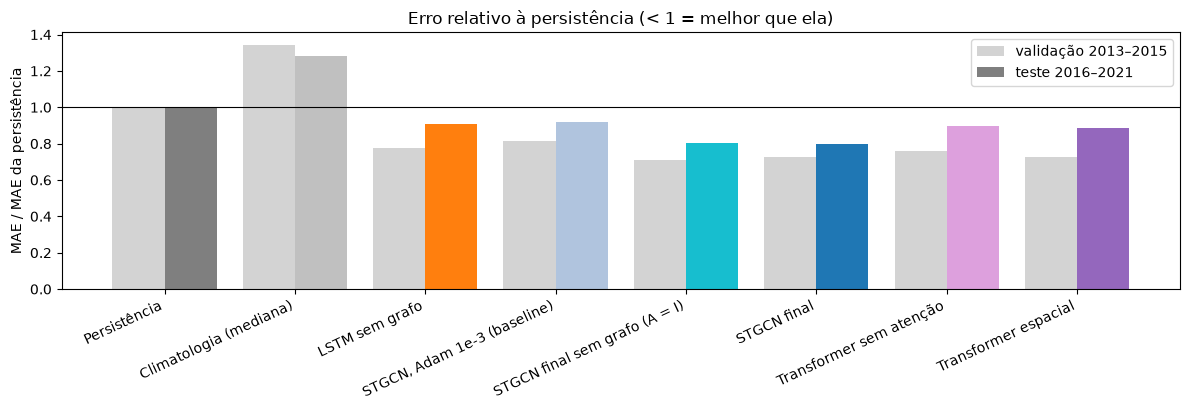

In [3]:
rel = (media['mae'] / media['mae'].xs('persistencia', level='modelo')).unstack('particao')
rel = rel.loc[ordem, ['validacao', 'teste']]
x = np.arange(len(ordem))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(x - 0.2, rel['validacao'], 0.4, color='lightgray', label='validação 2013–2015')
ax.bar(x + 0.2, rel['teste'], 0.4, color=[cores[m] for m in ordem], label='teste 2016–2021')
ax.axhline(1, color='k', lw=0.8)
ax.set(xticks=x, ylabel='MAE / MAE da persistência', title='Erro relativo à persistência (< 1 = melhor que ela)')
ax.set_xticklabels([nomes[m] for m in ordem], rotation=25, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** sim, a ordem se mantém, e a validação não enganou. Nos dois períodos, os STGCN com o protocolo novo ficam em primeiro (cerca de 0,71 a 0,73 da persistência na validação e 0,80 no teste), seguidos pelo LSTM e pelo STGCN com o protocolo antigo. A exceção é o **Transformer espacial**: na validação, ele estava junto dos STGCN (0,72 da persistência), e no teste caiu para perto do LSTM (0,88). Todos perdem vantagem no teste, mas ele é o que mais perde (+0,16, contra +0,07 dos STGCN e +0,13 do LSTM). A climatologia é a pior nos dois. A vantagem relativa diminui no teste porque, num período calmo, repetir a última semana (quase sempre zero) já é muito bom.

### Pergunta 3: como os modelos se saem em surto e em calmaria?

As semanas-alvo são de surto quando a taxa média estadual passa do limiar de 1,65 (quantil de 90% do treino). O viés é a média de (previsto − real), e um viés negativo quer dizer que o modelo subestima.

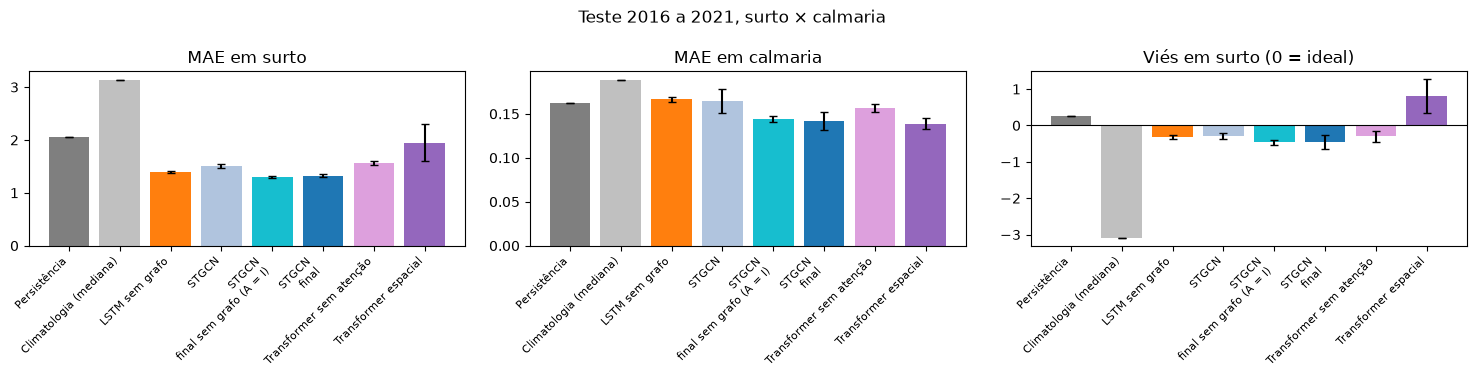

In [4]:
regimes = ['surto', 'calmaria']
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(ordem))
for ax, (c, titulo) in zip(eixos, [('mae_surto', 'MAE em surto'), ('mae_calmaria', 'MAE em calmaria'),
                                    ('vies_surto', 'Viés em surto (0 = ideal)')]):
    ax.bar(x, teste_m[c], yerr=teste_d[c], capsize=3, color=[cores[m] for m in ordem])
    ax.set(xticks=x, title=titulo)
    ax.set_xticklabels([nomes[m].split(',')[0].replace(' final', '\nfinal') for m in ordem],
                       rotation=45, ha='right', fontsize=8)
eixos[2].axhline(0, color='k', lw=0.8)
fig.suptitle('Teste 2016 a 2021, surto × calmaria')
plt.tight_layout()
plt.show()

**Conclusão:**
- **Calmaria (96% das semanas do teste):** o STGCN final erra menos que todos (MAE 0,142, contra 0,163 da persistência e 0,167 do LSTM), e o viés dele é zero.
- **Surto:** a vantagem é maior. O MAE em surto cai de 2,06 (persistência) e 1,39 (LSTM) para 1,33. Mesmo assim, o modelo **subestima os surtos**: o viés é de −0,45 por município e semana. É o efeito previsto na task 20 (treinar em `log1p` puxa as previsões altas para baixo). A persistência, ao contrário, superestima (+0,25), porque continua repetindo o pico quando a curva já está caindo.
- **Transformer:** é o contrário dos outros modelos. Na calmaria, ele tem o **menor erro de todos** (0,139). No surto, ele **superestima** (viés de +0,81) e varia muito entre as seeds (MAE em surto de 1,57 a 2,24). A versão sem atenção não tem esse problema (viés −0,30, MAE em surto 1,57). A atenção junta a informação do estado inteiro (`03b_transformer`, pergunta 3), e no surto de 2016 esse sinal estadual empurrou a previsão de muitos municípios para cima ao mesmo tempo.
- **Ressalva:** no teste, só 13 semanas passam do limiar de surto, todas no início de 2016. A análise de surto se apoia nesse único episódio e deve ser lida como indicativa.

### Pergunta 4: o modelo acompanha a curva estadual ao longo do teste?

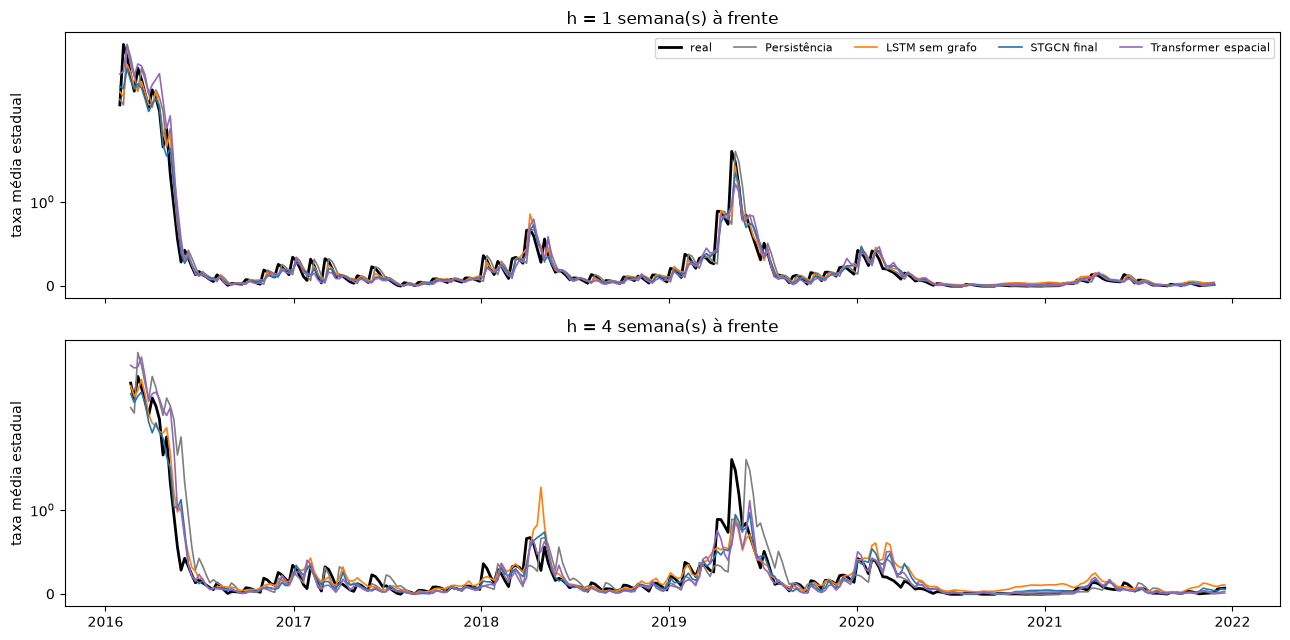

In [5]:
mostrar = ['persistencia', 'lstm', 'stgcn_final', 'transformer']
fig, eixos = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, h in zip(eixos, [1, 4]):
    s = series[series['h'] == h].sort_values('data')
    ax.plot(s['data'], s['real'], color='k', lw=2, label='real')
    for m in mostrar:
        ax.plot(s['data'], s[m], color=cores[m], lw=1.2, label=nomes[m])
    ax.set(ylabel='taxa média estadual', title=f'h = {h} semana(s) à frente', yscale='symlog')
eixos[0].legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

**Conclusão:** em h = 1, todos acompanham a curva de perto. Em h = 4, a persistência fica **atrasada**: ela repete o valor de 4 semanas antes, então o pico dela aparece depois do real (fica claro em 2019) e a queda de 2016 também chega atrasada. Os modelos treinados não têm esse atraso, mas ficam abaixo do real nos picos, de forma mais visível em 2018 e 2019. É a subestimação da pergunta 3. Nos anos calmos, todos ficam próximos do real. O LSTM superestima um pouco 2020 e 2021 em h = 4. O Transformer é o único que passa **acima** do real no surto de 2016: em h = 4, ele prevê de 4,8 a 5,6 em fevereiro e março, quando o real ficou entre 3,0 e 4,2. O eixo está em escala simétrica-log para mostrar os períodos calmos e o pico no mesmo gráfico.

### Pergunta 5: onde o modelo erra mais?

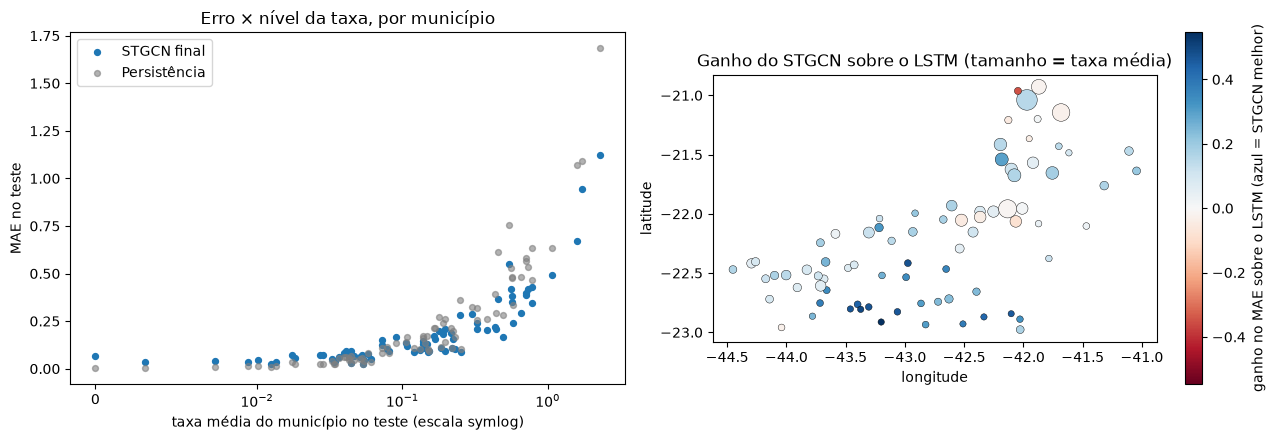

STGCN final melhor que o LSTM em 87% dos municípios; melhor que a persistência em 61%.


In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
ax = eixos[0]
ax.scatter(munic['taxa_media'], munic['stgcn_final'], color=cores['stgcn_final'], label='STGCN final', s=18)
ax.scatter(munic['taxa_media'], munic['persistencia'], color=cores['persistencia'], label='Persistência', s=18, alpha=0.6)
ax.set_xscale('symlog', linthresh=0.01)
ax.set(xlabel='taxa média do município no teste (escala symlog)',
       ylabel='MAE no teste', title='Erro × nível da taxa, por município')
ax.legend()

ax = eixos[1]
ganho = 1 - munic['stgcn_final'] / munic['lstm']
lim = np.abs(ganho).max()
sc = ax.scatter(munic['longitude'], munic['latitude'], c=ganho, cmap='RdBu', vmin=-lim, vmax=lim,
                s=20 + 200 * munic['taxa_media'] / munic['taxa_media'].max(), edgecolors='k', linewidths=0.3)
fig.colorbar(sc, ax=ax, label='ganho no MAE sobre o LSTM (azul = STGCN melhor)')
ax.set(xlabel='longitude', ylabel='latitude', title='Ganho do STGCN sobre o LSTM (tamanho = taxa média)')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()
print(f"STGCN final melhor que o LSTM em {(munic['stgcn_final'] < munic['lstm']).mean():.0%} dos municípios; "
      f"melhor que a persistência em {(munic['stgcn_final'] < munic['persistencia']).mean():.0%}.")

**Conclusão:** o erro acompanha o nível da taxa: a correlação entre o MAE do STGCN e a taxa média do município é 0,96. Os municípios com mais internações são os que concentram o erro. O STGCN é melhor que o LSTM em 87% dos municípios. O ganho é mais forte no sul do estado (região metropolitana e litoral). No norte, onde estão alguns dos municípios de taxa mais alta, há empates e algumas perdas. Contra a persistência, ele vence em 61% dos municípios. Nos municípios em que a taxa fica quase sempre em zero, repetir a última semana é praticamente imbatível. A vantagem do modelo está nos municípios com dengue de verdade, que são justamente os que importam.

### Resumo: tabela final congelada (teste, 3 seeds)

| Modelo | MAE | RMSE | MAE surto | MAE calmaria |
| --- | --- | --- | --- | --- |
| Persistência | 0,234 | 1,276 | 2,057 | 0,163 |
| Climatologia (mediana) | 0,300 | 1,662 | 3,141 | 0,189 |
| LSTM sem grafo | 0,213 ± 0,003 | 0,988 ± 0,012 | 1,387 ± 0,021 | 0,167 ± 0,003 |
| STGCN, Adam 1e-3 (baseline) | 0,216 ± 0,013 | 0,982 ± 0,018 | 1,512 ± 0,033 | 0,165 ± 0,014 |
| STGCN final sem grafo | 0,188 ± 0,003 | 0,922 ± 0,013 | 1,300 ± 0,023 | 0,144 ± 0,004 |
| **STGCN final** | **0,187 ± 0,011** | **0,923 ± 0,015** | **1,326 ± 0,025** | **0,142 ± 0,011** |
| Transformer sem atenção | 0,210 ± 0,004 | 1,009 ± 0,013 | 1,571 ± 0,038 | 0,157 ± 0,005 |
| Transformer espacial | 0,207 ± 0,017 | 1,022 ± 0,079 | 1,950 ± 0,344 | 0,139 ± 0,006 |

- O STGCN final supera todos os baselines no teste: −20% no MAE e −36% no MAE em surto em relação à persistência, e −12% no MAE em relação ao LSTM.
- O ganho vem do modelo convolucional no tempo e do protocolo de treino (AdamW, warmup + cosseno, Huber). O grafo geográfico não acrescentou nada mensurável.
- O Transformer espacial (task 23), com o mesmo protocolo, empatou com o STGCN na validação, mas ficou 10% atrás no teste. Ele é o melhor na calmaria e o mais instável no surto, que ele superestima. A atenção mostrou que existe sinal entre municípios, mas um sinal estadual, não geográfico.
- O STGCN subestima os surtos (viés −0,45), e o Transformer superestima (+0,81). Quem usar a previsão como alerta precisa saber disso.
- Cada modelo foi avaliado no teste uma única vez. Os arquivos `results/teste_final*.csv` são a referência para o README.